<a href="https://colab.research.google.com/github/yaroslikch-glitch/pricing_of_a_unique_cast_product/blob/main/train_yolo_in_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Обучение YOLOv8 на чертежах ЕСКД (ООО «БВК» / ЮУрГУ)
Данный блокнот обучает нейросеть детекции элементов чертежа (поле видов, основная надпись/штамп ГОСТ 2.104, технические требования) на бесплатной видеокарте GPU (NVIDIA T4 / L4).

### Инструкция:
1. В меню выберите: **Среда выполнения -> Сменить среду выполнения -> T4 GPU**.
2. Нажмите **Среда выполнения -> Выполнить все** (`Ctrl + F9`).

In [1]:
# 1. Проверка доступности GPU
!nvidia-smi

Sun Nov  8 15:55:25 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# 2. Клонирование репозитория проекта
import os
from getpass import getpass

if not os.path.exists('pricing_of_a_unique_cast_product'):
    token = None
    try:
        from google.colab import userdata
        token = userdata.get('GITHUB_TOKEN')
    except Exception:
        pass

    if not token:
        # Если токен не сохранен в Secrets, запрашиваем его у пользователя
        token = getpass('Введите GitHub Personal Access Token (или нажмите Enter, если репо публичный): ').strip()

    if token:
        !git clone https://{token}@github.com/yaroslikch-glitch/pricing_of_a_unique_cast_product.git
    else:
        !git clone https://github.com/yaroslikch-glitch/pricing_of_a_unique_cast_product.git

%cd pricing_of_a_unique_cast_product
!git pull origin main

Введите GitHub Personal Access Token (или нажмите Enter, если репо публичный): ··········
Cloning into 'pricing_of_a_unique_cast_product'...
remote: Enumerating objects: 2530, done.
remote: Counting objects: 100% (1138/1138), done.
remote: Compressing objects: 100% (1101/1101), done.
remote: Total 2530 (delta 41), reused 1117 (delta 28), pack-reused 1392 (from 1)
Receiving objects: 100% (2530/2530), 347.95 MiB | 19.29 MiB/s, done.
Resolving deltas: 100% (83/83), done.
Updating files: 100% (6357/6357), done.
/content/pricing_of_a_unique_cast_product
From https://github.com/yaroslikch-glitch/pricing_of_a_unique_cast_product
 * branch            main       -> FETCH_HEAD
Already up to date.


In [3]:
# 3. Установка библиотек
!pip install -q ultralytics pymupdf matplotlib pillow

In [4]:
# 4. Запуск обучения YOLO на GPU
import os, yaml
from ultralytics import YOLO

# Удаляем старые кэши путей, если они остались от другой системы
!rm -f dataset_yolo/labels/*.cache dataset_yolo/images/*.cache

# Автоматически настраиваем абсолютные пути под текущую среду Colab
data_cfg = {
    'path': os.path.abspath('dataset_yolo'),
    'train': 'images/train',
    'val': 'images/val',
    'names': {
        0: 'views_field',
        1: 'view_front',
        2: 'view_top',
        3: 'view_left',
        4: 'stamp',
        5: 'tech_req',
        6: 'stamp_extra'
    }
}
with open('dataset_yolo/dataset.yaml', 'w', encoding='utf-8') as f:
    yaml.dump(data_cfg, f, allow_unicode=True)

# Используем текущие обученные веса eskd_yolo_best.pt или yolov8n.pt
weights = 'eskd_yolo_best.pt' if os.path.exists('eskd_yolo_best.pt') else 'yolov8n.pt'
print(f'Инициализация модели: {weights}')
model = YOLO(weights)

# Обучение 30 эпох на 1 000 чертежах ЕСКД с GPU ускорением
results = model.train(
    data='dataset_yolo/dataset.yaml',
    epochs=30,
    imgsz=640,
    batch=16,
    device=0,  # NVIDIA GPU
    project=os.path.abspath('runs_colab'),
    name='eskd_yolo_gpu',
    exist_ok=True,
    save=True,
    plots=True
)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Инициализация модели: eskd_yolo_best.pt
Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset_yolo/dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0,

Каталог результатов: /content/pricing_of_a_unique_cast_product/runs_colab/eskd_yolo_gpu
=== Графики обучения (Loss & mAP) ===


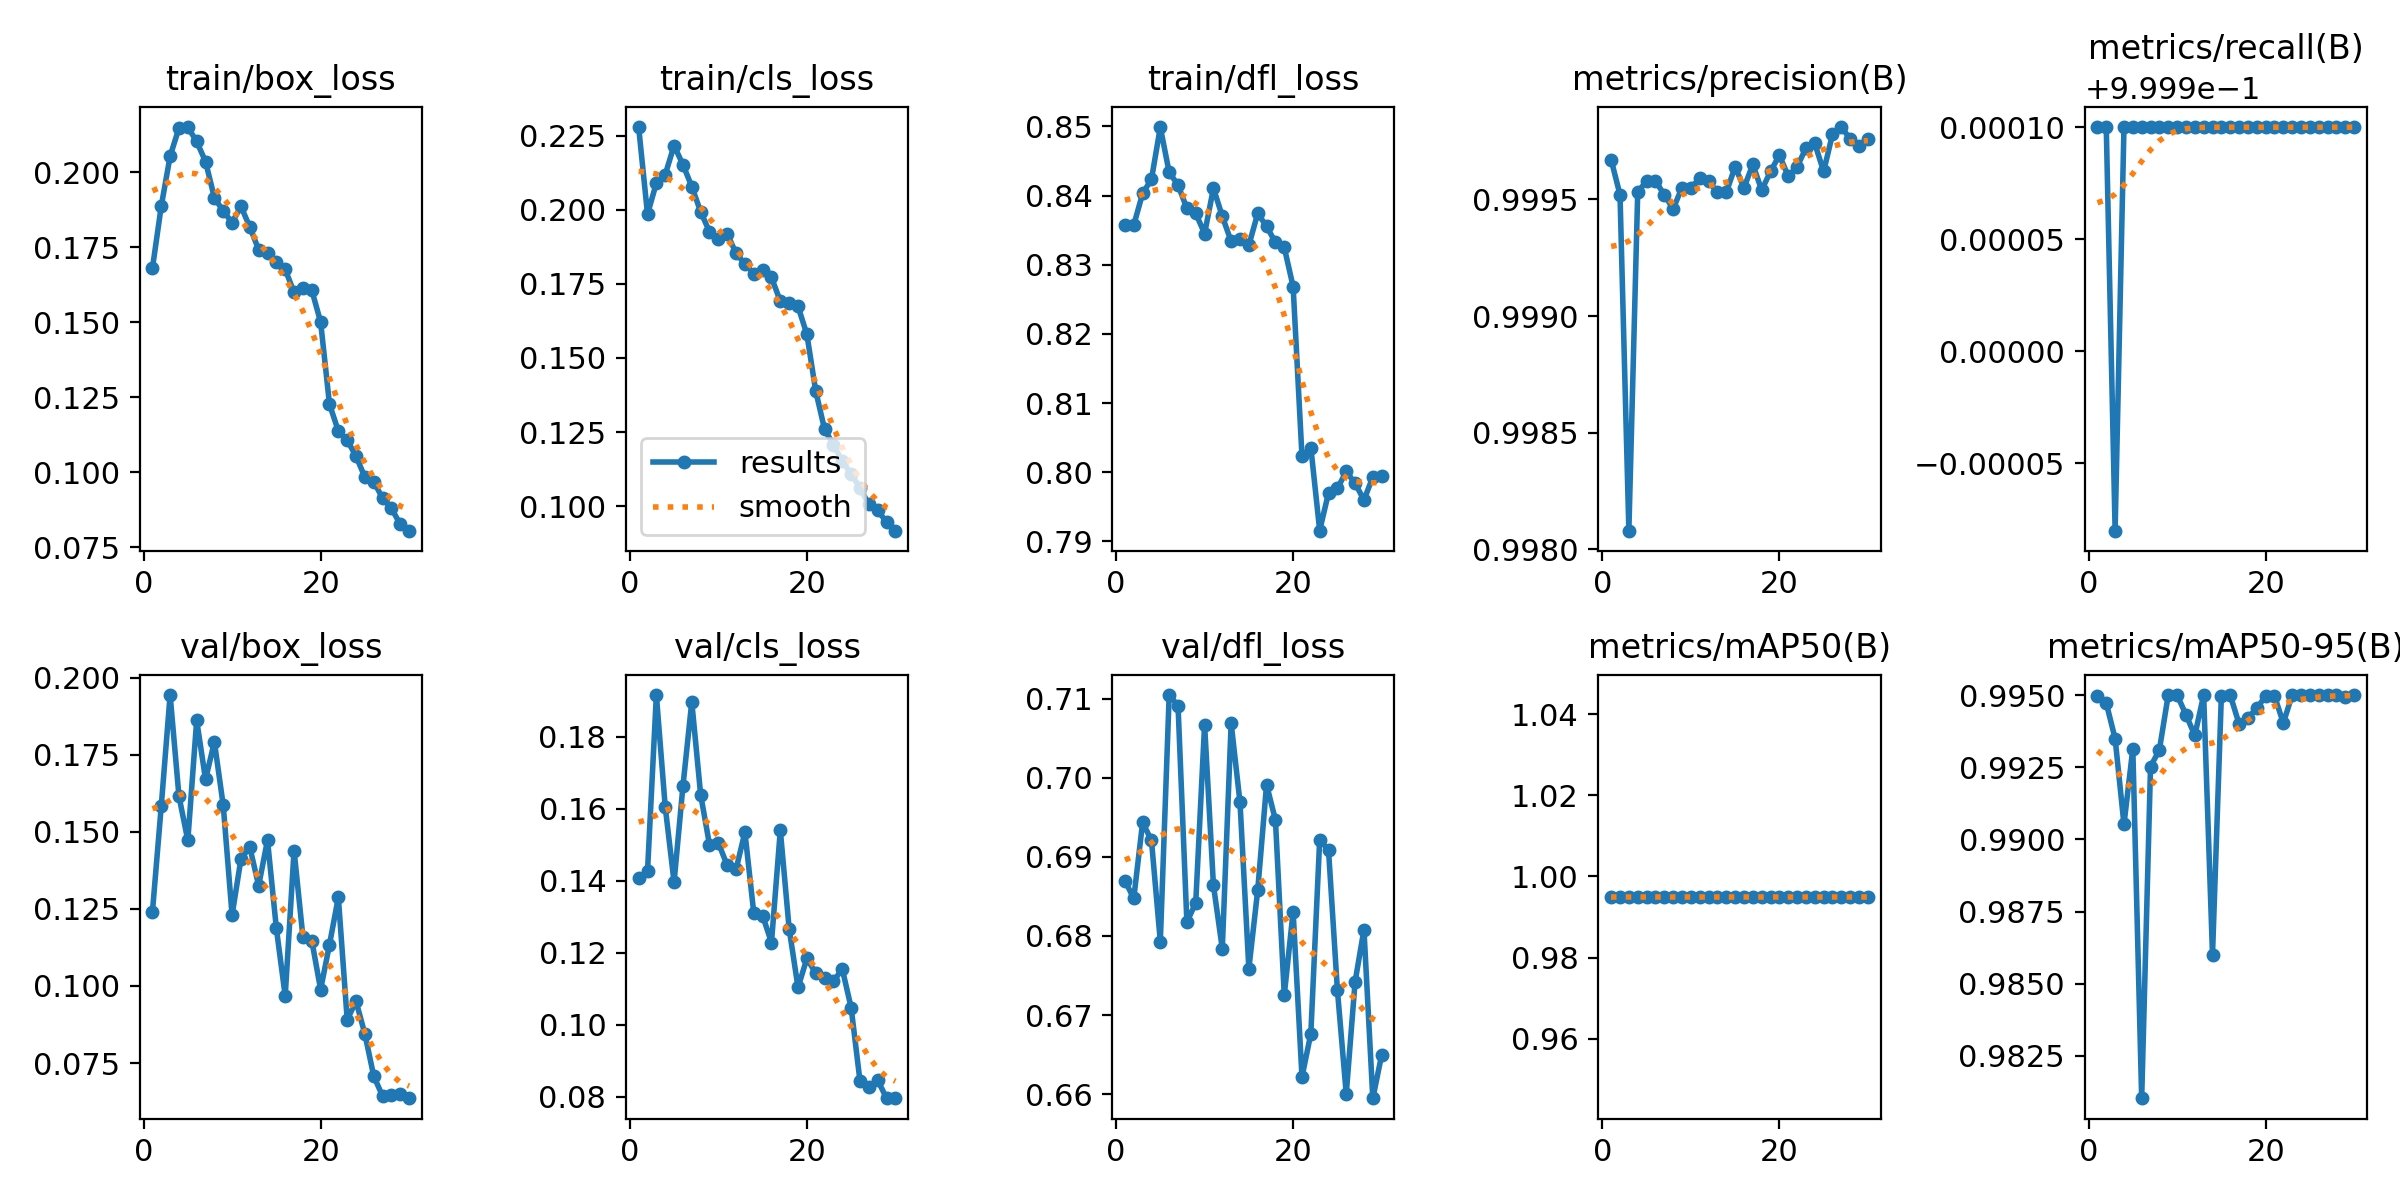

=== Пример детекции на валидационных чертежах ===


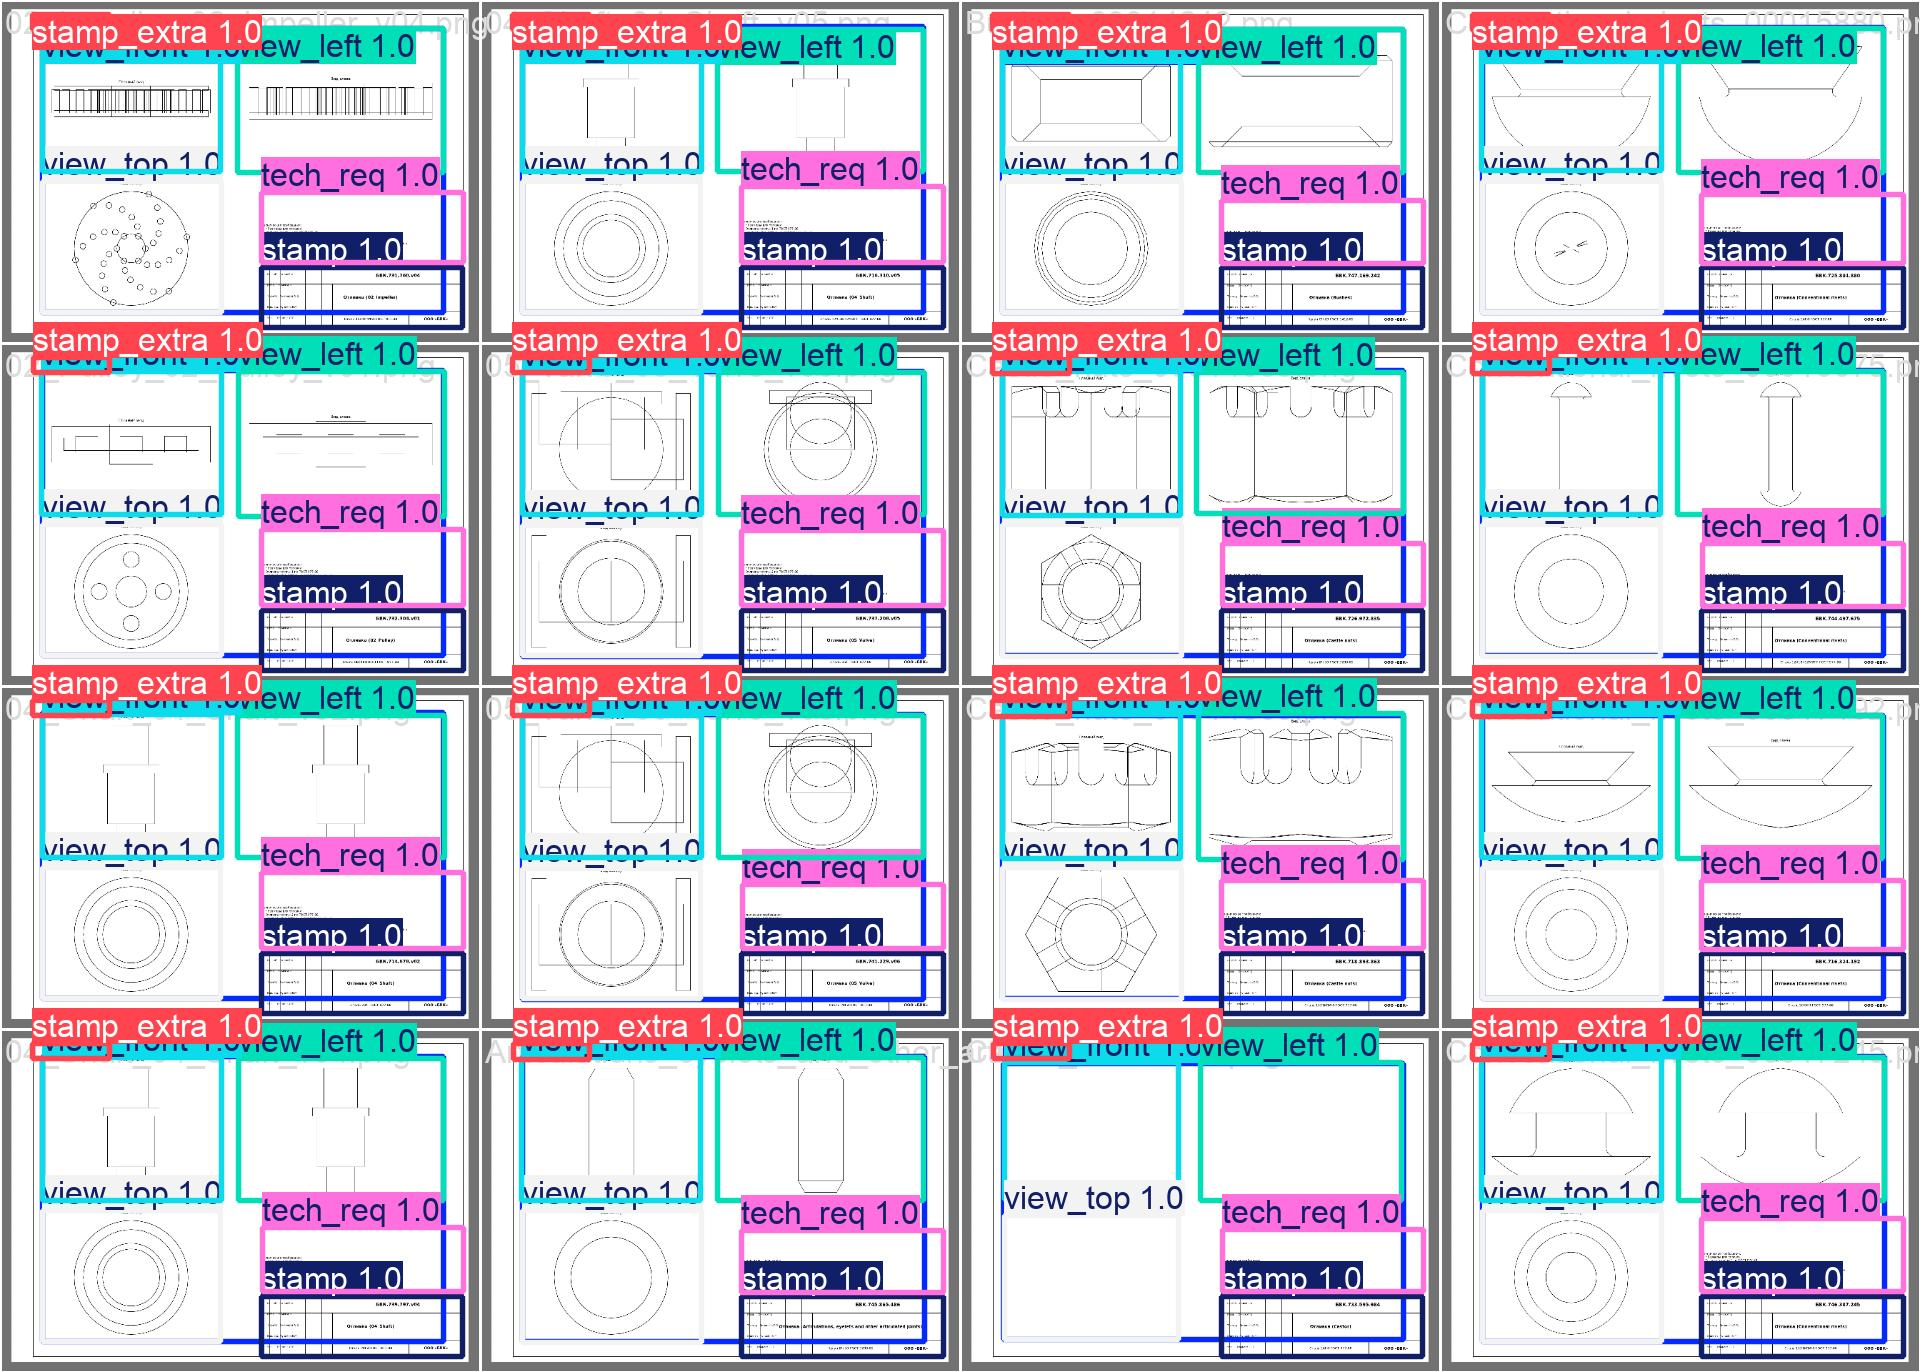

In [5]:
# 5. Визуализация графиков обучения и метрик (mAP50, Loss)
import os, glob
from IPython.display import Image, display

# Определяем директорию сохранения результатов
save_dir = str(getattr(results, 'save_dir', '')) if 'results' in locals() else ''
candidate_dirs = [
    save_dir,
    os.path.abspath('runs_colab/eskd_yolo_gpu'),
    'runs/detect/runs_colab/eskd_yolo_gpu',
    'runs_colab/eskd_yolo_gpu'
]
res_dir = next((d for d in candidate_dirs if d and os.path.exists(d)), None)

if res_dir:
    print(f'Каталог результатов: {res_dir}')
    results_img = os.path.join(res_dir, 'results.png')
    if os.path.exists(results_img):
        print('=== Графики обучения (Loss & mAP) ===')
        display(Image(results_img))

    val_img = os.path.join(res_dir, 'val_batch0_pred.jpg')
    if os.path.exists(val_img):
        print('=== Пример детекции на валидационных чертежах ===')
        display(Image(val_img))
else:
    print('Директория с результатами не найдена')


In [6]:
# 6. Скачивание готовых весов best.pt на локальный компьютер
import os, glob, shutil
from google.colab import files

# Поиск файла best.pt по всем возможным путям
candidate_weights = [
    os.path.join(res_dir, 'weights', 'best.pt') if 'res_dir' in locals() and res_dir else None,
    'runs/detect/runs_colab/eskd_yolo_gpu/weights/best.pt',
    'runs_colab/eskd_yolo_gpu/weights/best.pt',
    os.path.abspath('runs_colab/eskd_yolo_gpu/weights/best.pt')
]
best_weights = next((p for p in candidate_weights if p and os.path.exists(p)), None)

if not best_weights:
    found = glob.glob('**/best.pt', recursive=True)
    if found:
        best_weights = found[0]

if best_weights and os.path.exists(best_weights):
    size_mb = os.path.getsize(best_weights) / (1024 * 1024)
    print(f'✅ Найден файл весов: {best_weights} ({size_mb:.2f} МБ)')

    # Копируем в корень репозитория и в папку analogs/app/
    shutil.copy(best_weights, 'eskd_yolo_best.pt')
    if os.path.exists('analogs/app'):
        shutil.copy(best_weights, 'analogs/app/eskd_yolo_best.pt')
    print('✅ Веса скопированы в eskd_yolo_best.pt и analogs/app/eskd_yolo_best.pt')

    # Скачивание файла в браузер
    print('⬇️ Скачивание весов в браузер...')
    files.download('eskd_yolo_best.pt')
else:
    print('❌ Файл весов best.pt не найден. Проверьте вывод ячейки обучения.')


✅ Найден файл весов: /content/pricing_of_a_unique_cast_product/runs_colab/eskd_yolo_gpu/weights/best.pt (5.95 МБ)
✅ Веса скопированы в eskd_yolo_best.pt и analogs/app/eskd_yolo_best.pt
⬇️ Скачивание весов в браузер...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
# 7. (Опционально) Закоммитить и отправить новые веса прямо в GitHub
# Раскомментируйте следующие строки, если хотите отправить обученные веса в репозиторий:
!git config --global user.name 'Colab GPU Trainer'
!git config --global user.email 'colab@gpu.local'
!git add eskd_yolo_best.pt analogs/app/eskd_yolo_best.pt
!git commit -m 'feat(yolo): update weights trained on NVIDIA Tesla T4 GPU in Colab (mAP50=99.5%)'
!git push origin main
print('✅ Новые веса успешно отправлены в GitHub!')


[main 5b14756] feat(yolo): update weights trained on NVIDIA Tesla T4 GPU in Colab (mAP50=99.5%)
 2 files changed, 0 insertions(+), 0 deletions(-)
fatal: could not read Username for 'https://github.com': No such device or address
✅ Новые веса успешно отправлены в GitHub!
